<a href="https://colab.research.google.com/github/tensor-sg/torch-agentic-scripts/blob/beta/torch_neural_network_base1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount(force_remount=True,mountpoint="/content/drive")
base_path="/content/drive/My Drive/ml_repo/data_resource"

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from torch.utils.data import TensorDataset,DataLoader

In [3]:
real_estate_data=pd.read_csv(f"{base_path}/real_estate_dataset.csv")

In [4]:
real_estate_data

,ID,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,1,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,2,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,3,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,4,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,5,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523
...,...,...,...,...,...,...,...,...,...,...,...,...
495,496,138.338057,2,2,2,1967,1,0,16,4.296086,5.562583,488496.350722
496,497,195.914028,2,3,1,1977,0,1,45,7.406261,2.845105,657736.921717
497,498,69.433659,1,1,2,2004,0,0,18,8.629724,6.263264,405324.950201
498,499,293.598702,5,1,3,1940,1,0,41,5.318891,16.990684,773035.968028


In [5]:
real_estate_data.set_index("ID",inplace=True)

In [6]:
real_estate_data

,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
ID,,,,,,,,,,,
1,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
2,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
3,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
4,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
5,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523
...,...,...,...,...,...,...,...,...,...,...,...
496,138.338057,2,2,2,1967,1,0,16,4.296086,5.562583,488496.350722
497,195.914028,2,3,1,1977,0,1,45,7.406261,2.845105,657736.921717
498,69.433659,1,1,2,2004,0,0,18,8.629724,6.263264,405324.950201


In [7]:
real_estate_data.shape

(500, 11)

In [8]:
real_estate_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500 entries, 1 to 500
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Square_Feet         500 non-null    float64
 1   Num_Bedrooms        500 non-null    int64  
 2   Num_Bathrooms       500 non-null    int64  
 3   Num_Floors          500 non-null    int64  
 4   Year_Built          500 non-null    int64  
 5   Has_Garden          500 non-null    int64  
 6   Has_Pool            500 non-null    int64  
 7   Garage_Size         500 non-null    int64  
 8   Location_Score      500 non-null    float64
 9   Distance_to_Center  500 non-null    float64
 10  Price               500 non-null    float64
dtypes: float64(4), int64(7)
memory usage: 46.9 KB


In [9]:
X=torch.FloatTensor(real_estate_data.drop('Price',axis=1).dropna().values)
Y=torch.FloatTensor(real_estate_data['Price'].dropna().values.reshape(-1,1))
X_mean=X.mean()
Y_mean=Y.mean()
X_std=X.std()
Y_std=Y.std()
X_scaled=(X-X_mean)/(X_std+1e-8)
Y_scaled=(Y-Y_mean)/(Y_std+1e-8)
X=X_scaled
Y=Y_scaled

In [10]:
class HousingLinearModel(nn.Module):

  def __init__(self,input_features,output_features):
    super().__init__()#!super class intializing
    self.linear=nn.Linear(in_features=input_features,
                          out_features=output_features)

  def forward_L1(self,x):
    y_pred=self.linear(x)
    return y_pred




In [11]:
epochs=100
torch.manual_seed(150)

housing_model2 = HousingLinearModel(10, 1)

criterion = nn.MSELoss()

optimizer = torch.optim.SGD(
    housing_model2.parameters(),
    lr=0.01
)



In [12]:
error_log = []

for epoch_i in range(epochs):

    optimizer.zero_grad()

    prediction_i = housing_model2.forward_L1(X_scaled)

    loss_i = criterion(prediction_i, Y_scaled)

    loss_i.backward()

    optimizer.step()

    error_log.append(loss_i.item())

error_log

[1.1652048826217651,
 1.0960774421691895,
 1.0538973808288574,
 1.0281286239624023,
 1.0123547315597534,
 1.0026676654815674,
 0.9966878890991211,
 0.9929656386375427,
 0.9906185269355774,
 0.9891087412834167,
 0.9881090521812439,
 0.9874200224876404,
 0.9869204163551331,
 0.9865359663963318,
 0.9862218499183655,
 0.9859506487846375,
 0.9857054948806763,
 0.9854763746261597,
 0.9852570295333862,
 0.9850436449050903,
 0.9848339557647705,
 0.9846265912055969,
 0.9844207763671875,
 0.9842157363891602,
 0.9840115308761597,
 0.9838076233863831,
 0.9836040735244751,
 0.9834007024765015,
 0.9831975698471069,
 0.9829944968223572,
 0.9827917814254761,
 0.9825891256332397,
 0.982386589050293,
 0.9821841716766357,
 0.9819818735122681,
 0.9817798137664795,
 0.9815777540206909,
 0.9813758730888367,
 0.9811741709709167,
 0.980972409248352,
 0.9807709455490112,
 0.9805697202682495,
 0.980368435382843,
 0.9801672101020813,
 0.9799662232398987,
 0.9797653555870056,
 0.9795646071434021,
 0.9793640971183

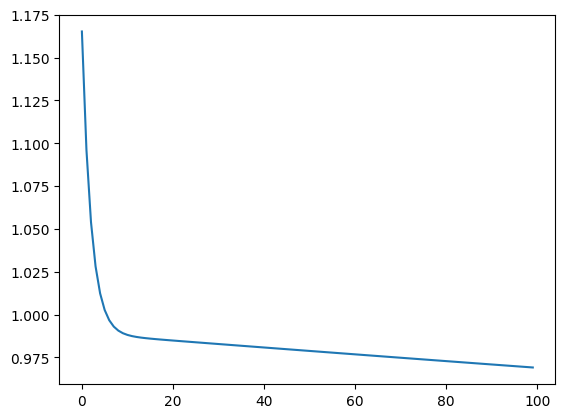

In [13]:
plt.plot(error_log)

In [14]:
X_t1=torch.randn(size=(5,5),requires_grad=True)#dyanmic computional object in place

In [15]:
Y_t1=2*X_t1**3+3*X_t1+2

In [16]:
Z_t1=Y_t1.mean()

In [17]:
Z_t1.backward()#chain rule apply X=>Y=>Z

In [18]:
X_t1#final value must be scalar

tensor([[-0.6039,  1.3380, -1.4701,  1.9773,  1.6270],
        [-0.1396, -0.2315, -0.5947,  0.5368,  0.2393],
        [ 0.9670,  1.4079,  0.3627,  0.2835,  0.1645],
        [-1.2436,  0.7674, -0.8140,  0.2248, -0.3170],
        [ 0.2578, -0.2922, -0.8417,  0.4741,  0.5019]], requires_grad=True)

In [19]:
#relu is 0 vs max as for negative values gradient could be smaller and smaller vanish and no improvment happens
#graident is colleciton of dError/dWeight
#dy/dx=dy/du*du/dx

In [20]:
#!iris classification and neural network


In [21]:
#!NOTE=>WITHOUT STD SCALAR OFTEN GRADIENT EXPLODE

In [22]:
# #
# unbiased=False means it calculates the population standard deviation, dividing by
# N
# N instead of
# N
# −
# 1
# N−1.
#dim is axis

In [23]:
iris_df1=pd.read_csv(f"{base_path}/iris_data.csv")

In [24]:
iris_df1

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


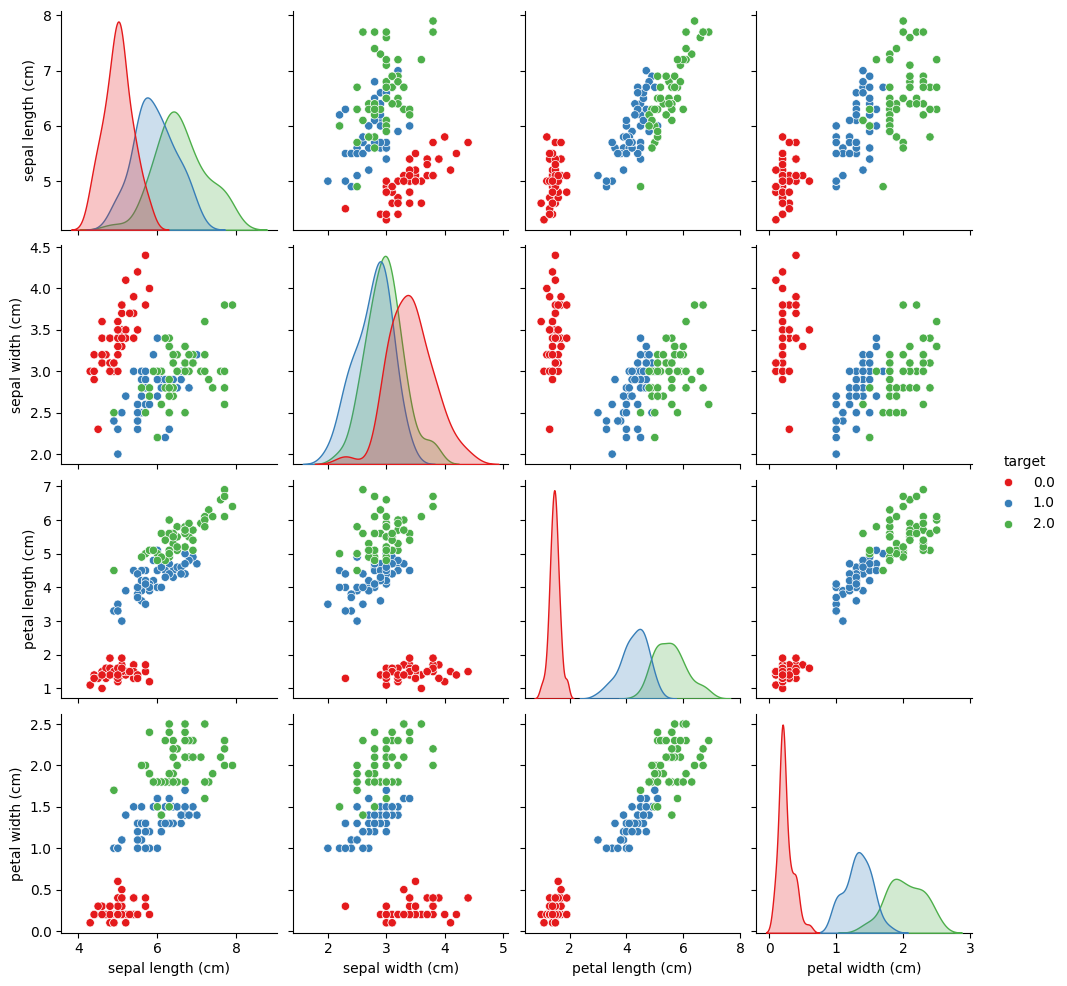

In [25]:
sns.pairplot(iris_df1,hue="target",palette="Set1")

<Axes: >

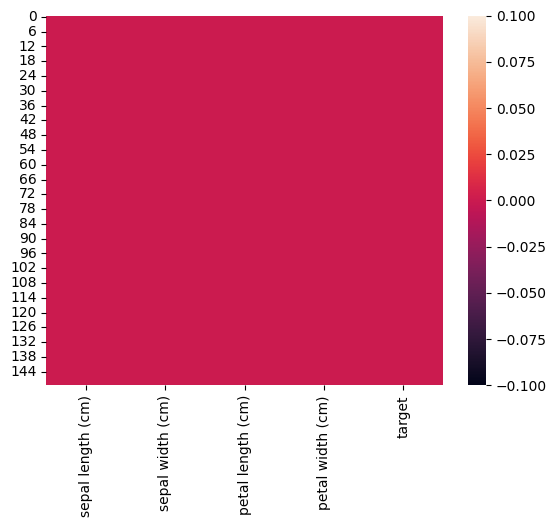

In [26]:
#standardization retains patterns
sns.heatmap(iris_df1.isna())

In [29]:
X_iris=torch.FloatTensor(iris_df1.drop("target",axis=1).values)
Y_iris=torch.LongTensor(iris_df1["target"])

In [30]:
iris_df1.shape

(150, 5)

In [31]:
X_iris.std(dim=0)

tensor([0.8281, 0.4336, 1.7644, 0.7632])

In [99]:
class IrisModel(nn.Module):
  def __init__(self,input_layer,hidden_layer_1=4,hidden_layer_2=4,output_layer=3):
    super().__init__()
    self.layer1=nn.Linear(in_features=input_layer,out_features=hidden_layer_1)
    self.layer2=nn.Linear(in_features=hidden_layer_1,out_features=hidden_layer_2)
    self.out=nn.Linear(in_features=hidden_layer_2,out_features=output_layer)
    #!defining dense fully connected layers
  def forward_propagate(self,x):
    x=F.relu((self.layer1(x)))#x into first layer via relu
    x=F.relu(self.layer2(x))  #value to second layer
    x=self.out(x)#last
    #epoch is full db pass
    #!passing through and automatic passing on
    return x

In [100]:
torch.manual_seed(32)
iris_model_L1=IrisModel(4)#loss.item

In [101]:
for entity_i in iris_model_L1.named_parameters():
  print(entity_i)

('layer1.weight', Parameter containing:
tensor([[ 0.3757, -0.2279, -0.0859,  0.2857],
        [-0.3870,  0.0793,  0.1481, -0.4771],
        [ 0.0874, -0.1746,  0.4485,  0.0219],
        [ 0.3782,  0.2254,  0.1929, -0.4741]], requires_grad=True))
('layer1.bias', Parameter containing:
tensor([ 0.4319, -0.4087,  0.2177,  0.2271], requires_grad=True))
('layer2.weight', Parameter containing:
tensor([[-0.0033,  0.4308, -0.1323, -0.2951],
        [ 0.1646, -0.1114, -0.4213, -0.3553],
        [-0.3191,  0.1440, -0.3496,  0.2280],
        [ 0.3867, -0.2029,  0.2828,  0.0105]], requires_grad=True))
('layer2.bias', Parameter containing:
tensor([ 0.3187, -0.0630, -0.3122,  0.3781], requires_grad=True))
('out.weight', Parameter containing:
tensor([[-0.3075,  0.1161,  0.2849, -0.3619],
        [-0.4545,  0.2794, -0.4941, -0.3732],
        [ 0.2167, -0.1676,  0.3529, -0.1080]], requires_grad=True))
('out.bias', Parameter containing:
tensor([ 0.0805, -0.2762,  0.0989], requires_grad=True))


In [102]:
#loss function handle Softmax internally. like sigmoid softmax are applied via the loss function and is embedded within the loss function

In [103]:
#one hot encoding and multiple out columns and use max % via softmax for output,if you use cross entropy then do it

In [104]:
criterion_cls=nn.CrossEntropyLoss()
optimzer_clas=torch.optim.Adam(iris_model_L1.parameters(),lr=0.001)

In [105]:
iris_model_L1.parameters()
for data in iris_model_L1.named_parameters():
  print(data)

('layer1.weight', Parameter containing:
tensor([[ 0.3757, -0.2279, -0.0859,  0.2857],
        [-0.3870,  0.0793,  0.1481, -0.4771],
        [ 0.0874, -0.1746,  0.4485,  0.0219],
        [ 0.3782,  0.2254,  0.1929, -0.4741]], requires_grad=True))
('layer1.bias', Parameter containing:
tensor([ 0.4319, -0.4087,  0.2177,  0.2271], requires_grad=True))
('layer2.weight', Parameter containing:
tensor([[-0.0033,  0.4308, -0.1323, -0.2951],
        [ 0.1646, -0.1114, -0.4213, -0.3553],
        [-0.3191,  0.1440, -0.3496,  0.2280],
        [ 0.3867, -0.2029,  0.2828,  0.0105]], requires_grad=True))
('layer2.bias', Parameter containing:
tensor([ 0.3187, -0.0630, -0.3122,  0.3781], requires_grad=True))
('out.weight', Parameter containing:
tensor([[-0.3075,  0.1161,  0.2849, -0.3619],
        [-0.4545,  0.2794, -0.4941, -0.3732],
        [ 0.2167, -0.1676,  0.3529, -0.1080]], requires_grad=True))
('out.bias', Parameter containing:
tensor([ 0.0805, -0.2762,  0.0989], requires_grad=True))


In [106]:
from sklearn.model_selection import train_test_split

In [107]:
X_iris_train,X_iris_test,Y_iris_train,Y_iris_test=train_test_split(X_iris,Y_iris,test_size=0.33,random_state=101)

In [108]:
# EPOCH=50
# loss_log=[]
# for epoch_i in range(EPOCH):
#   optimzer_clas.zero_grad()
#   y_pred=iris_model_L1.forward_propagate(X_iris_train)
#   loss=criterion_cls(y_pred,Y_iris_train)
#   loss.backward()
#   optimzer_clas.step()

In [109]:
# print(X_iris_train.dtype)
# print(Y_iris_train.dtype)
# print(y_pred.dtype)
# CrossEntropyLoss(input_logits, target_labels)

In [110]:
# print(y_pred.shape)
# print(Y_iris_train.shape)

In [111]:
# model = XGBRegressor(
#     n_estimators=300,
#     learning_rate=0.05,
#     max_depth=6,
#     objective="reg:squarederror",
#     eval_metric="rmse",
#     random_state=42,
#     n_jobs=-1
# )

In [112]:
# model = XGBClassifier(
#     n_estimators=300,
#     learning_rate=0.05,
#     max_depth=6,
#     objective="binary:logistic",
#     eval_metric="logloss",
#     random_state=42,
#     n_jobs=-1
# )

In [113]:
# objective="reg:squarederror",
# #     eval_metric="rmse",

# objective="binary:logistic",
# #     eval_metric="logloss",


# objective="multi:softmax",
# eval_metric="mlogloss",

In [114]:
from torch.utils.data import TensorDataset,DataLoader

In [115]:
iris_df1

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


In [116]:
X_iris2=iris_df1.drop("target",axis=1).values


In [117]:
Y_iris2=iris_df1["target"].values

In [118]:
tensor_iris_datset=TensorDataset(torch.FloatTensor(X_iris2),torch.LongTensor(Y_iris2))

In [119]:
data_loader_iris2=DataLoader(shuffle=True,batch_size=30,dataset=tensor_iris_datset)

In [120]:
for batch_x,batch_y in data_loader_iris2:
  print("X",batch_x,"\nY",batch_y,"\n")

X tensor([[4.6000, 3.4000, 1.4000, 0.3000],
        [6.9000, 3.2000, 5.7000, 2.3000],
        [6.8000, 3.0000, 5.5000, 2.1000],
        [5.5000, 2.4000, 3.7000, 1.0000],
        [6.2000, 2.9000, 4.3000, 1.3000],
        [6.0000, 2.9000, 4.5000, 1.5000],
        [4.9000, 3.0000, 1.4000, 0.2000],
        [6.1000, 2.8000, 4.0000, 1.3000],
        [5.6000, 2.7000, 4.2000, 1.3000],
        [6.3000, 3.3000, 4.7000, 1.6000],
        [5.4000, 3.9000, 1.3000, 0.4000],
        [6.3000, 2.5000, 4.9000, 1.5000],
        [7.2000, 3.0000, 5.8000, 1.6000],
        [6.4000, 2.8000, 5.6000, 2.1000],
        [6.7000, 3.0000, 5.2000, 2.3000],
        [4.6000, 3.1000, 1.5000, 0.2000],
        [5.4000, 3.0000, 4.5000, 1.5000],
        [5.8000, 4.0000, 1.2000, 0.2000],
        [5.1000, 3.5000, 1.4000, 0.2000],
        [6.1000, 2.9000, 4.7000, 1.4000],
        [6.4000, 2.9000, 4.3000, 1.3000],
        [5.0000, 3.2000, 1.2000, 0.2000],
        [6.1000, 3.0000, 4.6000, 1.4000],
        [6.8000, 3.2000, 5.9000,

In [121]:
#both batches and epochs

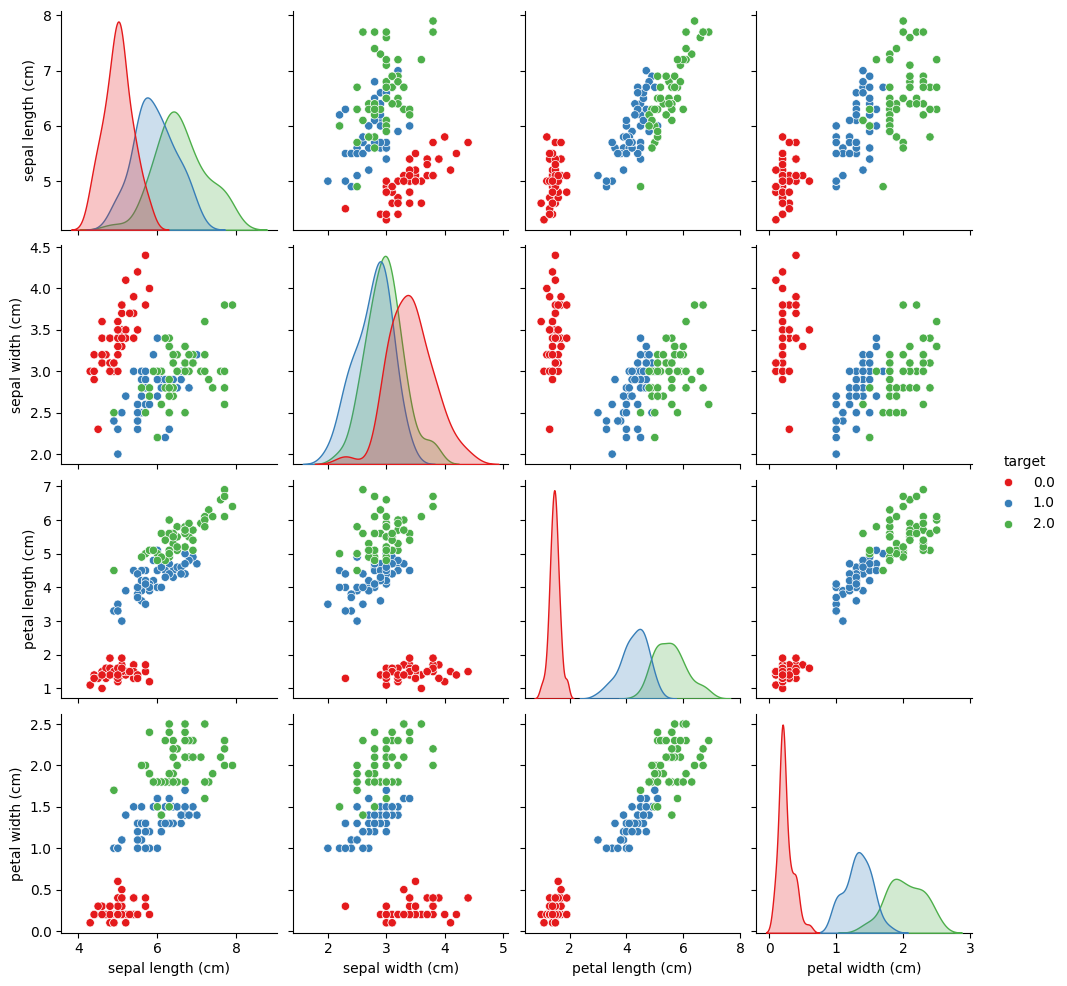

In [122]:
sns.pairplot(data=iris_df1,hue="target",palette="Set1")

In [123]:
# import torch.nn.functional as F

In [124]:
# class Irisnn(nn.Module):

#   def __init__(self,
#                input_layer,
#                hidden_layer_1,
#                hidden_layer_2,
#                output_layer):
#     #class initialization with constructor
#     super().__init__()
#     #!super class initilization
#     #self.forward_pass_1 is an instance attribute holding a callable object.
#     self.forward_pass_1=nn.Linear(in_features=input_layer,out_features=hidden_layer_1)#attribute itself is now an object ,ita
#     self.forward_pass_2=nn.ReLU(nn.Linear(in_features=hidden_layer_1,out_features=hidden_layer_2))
#     self.foward_pass_out=nn.Relu(nn.Linear(in_features=input_layer,out_features=hidden_layer_1))

#   def forward(self,x_input_vector):
#     y_pred=self.forward_pass_1()
#     y_pred=self.hidden_layer1


In [125]:
class Calculator:

    def __call__(self, x):
        return x + 10

calc = Calculator()

calc(5)  # 15

#it is dunder method

15

In [126]:
class Paradigm:

  def __init__(self,x):
    self.compute=x**2
  def __call__(self,x):
    return x**2+100


In [127]:
p1=Paradigm(5)

In [128]:
p1.compute

25

In [129]:
p1(11)#so it makes an object behave like a function basically auto call a functiojn

221

In [130]:
class Irisnn(nn.Module):

  def __init__(self,
               input_layer,
               hidden_layer_1,
               hidden_layer_2,
               output_layer):
    #class initialization with constructor
    super().__init__()
    #!super class initilization
    #self.forward_pass_1 is an instance attribute holding a callable object.
    self.fp1=nn.Linear(in_features=input_layer,
                                  out_features=hidden_layer_1)#attribute itself is now an object ,ita
    self.fp2=nn.Linear(in_features=hidden_layer_1,
                                          out_features=hidden_layer_2)
    self.out=nn.Linear(in_features=input_layer,
                                           out_features=hidden_layer_1)

  def forward(self,
              x_input_vector):
    y_pred=self.fp1(x_input_vector)
    y_pred=F.relu(self.fp2(y_pred))
    y_pred=F.relu(self.out(y_pred))
    return y_pred


In [131]:
iris_LM1=Irisnn(input_layer=4,hidden_layer_1=4,hidden_layer_2=4,output_layer=3)

In [132]:
y_pred_iris=iris_LM1.forward(X_iris_train)

In [133]:
y_pred_iris

tensor([[0.0000, 0.0486, 0.0000, 0.1213],
        [0.0000, 0.0000, 0.0000, 0.1508],
        [0.0000, 0.2160, 0.0093, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.1724],
        [0.0000, 0.0111, 0.0000, 0.0885],
        [0.0000, 0.1833, 0.0000, 0.1625],
        [0.0000, 0.0642, 0.0000, 0.1153],
        [0.0000, 0.0000, 0.0000, 0.1862],
        [0.0000, 0.0000, 0.0000, 0.1840],
        [0.0000, 0.1179, 0.0000, 0.0727],
        [0.0000, 0.0000, 0.0000, 0.1338],
        [0.0000, 0.1204, 0.0000, 0.0724],
        [0.0000, 0.2581, 0.0000, 0.2153],
        [0.0000, 0.2987, 0.0453, 0.0000],
        [0.0000, 0.1338, 0.0005, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.1788],
        [0.0000, 0.1270, 0.0000, 0.0560],
        [0.0000, 0.0000, 0.0000, 0.1696],
        [0.0000, 0.2160, 0.0093, 0.0000],
        [0.0000, 0.2852, 0.0142, 0.0000],
        [0.0000, 0.1371, 0.0000, 0.0042],
        [0.0000, 0.2758, 0.0408, 0.0000],
        [0.0000, 0.0808, 0.0000, 0.1743],
        [0.0000, 0.3348, 0.0524, 0

In [134]:
#the loss function has nested final activation/softmax/sigmoid

In [135]:
# # torch.optim.Adam(params=)
# nn.BCELoss()
# # nn.CrossEntropyLoss()

#define optimizer and step
#entropy
#loss.backward()
#optmizer step()

In [136]:
# BCEWithLogitsLoss()

In [137]:
X_iris_train.dtype

torch.float32

In [138]:
Y_iris_train

tensor([1, 0, 2, 0, 1, 2, 1, 0, 0, 1, 0, 1, 2, 2, 1, 0, 1, 0, 2, 2, 1, 2, 1, 2,
        0, 0, 0, 1, 0, 0, 0, 2, 0, 0, 2, 2, 0, 0, 2, 2, 2, 0, 1, 2, 0, 0, 2, 2,
        0, 1, 0, 2, 2, 0, 2, 1, 1, 2, 0, 2, 0, 1, 2, 0, 1, 0, 2, 1, 2, 0, 2, 2,
        2, 1, 0, 0, 2, 1, 0, 1, 2, 2, 2, 1, 0, 2, 0, 2, 1, 2, 2, 0, 2, 1, 1, 1,
        1, 1, 0, 1])

In [139]:
Y_iris_train.dtype #reshape -1,1 for proper n row 1 col structure

torch.int64

In [140]:
for param in iris_LM1.named_parameters():
  print(param,"\n")

('fp1.weight', Parameter containing:
tensor([[-0.0888,  0.4977,  0.0187,  0.4310],
        [-0.2972,  0.1240, -0.0858,  0.4531],
        [ 0.1668,  0.0360, -0.3196, -0.4245],
        [-0.1595,  0.2576, -0.2704, -0.2100]], requires_grad=True)) 

('fp1.bias', Parameter containing:
tensor([-0.4375,  0.4716,  0.4518, -0.2877], requires_grad=True)) 

('fp2.weight', Parameter containing:
tensor([[ 0.0161, -0.0278,  0.0887, -0.3249],
        [-0.3119, -0.0734, -0.3844,  0.0557],
        [-0.2556, -0.3952, -0.0247, -0.2095],
        [ 0.2066,  0.4065, -0.2953, -0.1562]], requires_grad=True)) 

('fp2.bias', Parameter containing:
tensor([-0.0883, -0.4873, -0.4850,  0.1994], requires_grad=True)) 

('out.weight', Parameter containing:
tensor([[-0.0325, -0.2556,  0.4778, -0.4983],
        [ 0.4419, -0.4774, -0.2944,  0.2737],
        [-0.1266, -0.1501, -0.3412,  0.1527],
        [ 0.4031,  0.1629,  0.4895, -0.3971]], requires_grad=True)) 

('out.bias', Parameter containing:
tensor([-0.4118, -0.2997

In [141]:
criterion_iris=nn.CrossEntropyLoss()

In [142]:
optimizer_iris=torch.optim.Adam(iris_LM1.parameters(),lr=0.1)

In [143]:
iris_LM1.parameters

<bound method Module.parameters of Irisnn(
  (fp1): Linear(in_features=4, out_features=4, bias=True)
  (fp2): Linear(in_features=4, out_features=4, bias=True)
  (out): Linear(in_features=4, out_features=4, bias=True)
)>

In [82]:
#EPOCH:PASS THROUGH COMPLETE TRAINING DATA

In [144]:
EPOCH=50

In [145]:
Y_iris_test

tensor([0, 0, 0, 2, 1, 2, 1, 1, 2, 0, 2, 0, 0, 2, 2, 1, 1, 1, 0, 2, 1, 0, 1, 1,
        1, 1, 1, 2, 0, 0, 2, 1, 2, 1, 2, 1, 1, 1, 1, 2, 0, 0, 0, 1, 1, 0, 2, 1,
        0, 1])

In [146]:
loss_log=[]
for epoch_i in range(50):
  optimizer_iris.zero_grad()#reset accumulation
  y_pred=iris_LM1.forward(X_iris_train)
  loss=criterion_iris(y_pred,Y_iris_train)
  loss_log.append(loss.item())
  loss.backward()
  optimizer_iris.step()#!weight bias update


In [147]:
print(y_pred.shape)
print(Y_iris_train.shape)
print(Y_iris_train.dtype)

torch.Size([100, 4])
torch.Size([100])
torch.int64


In [148]:
loss_log

[1.4159178733825684,
 1.2551965713500977,
 1.1939818859100342,
 1.2232675552368164,
 1.1183282136917114,
 1.062391996383667,
 1.0507380962371826,
 0.9950433373451233,
 0.9390968084335327,
 0.9611484408378601,
 0.9268071055412292,
 0.9040799736976624,
 0.9159267544746399,
 0.9012856483459473,
 0.8833152651786804,
 0.8873802423477173,
 0.881206750869751,
 0.8647316694259644,
 0.8658822774887085,
 0.8606617450714111,
 0.8447466492652893,
 0.8379677534103394,
 0.7480871677398682,
 0.52964186668396,
 0.4184812307357788,
 0.3586241602897644,
 0.3252498209476471,
 0.44856539368629456,
 0.323469877243042,
 0.2948334813117981,
 0.28375667333602905,
 0.25259894132614136,
 0.2364291548728943,
 0.24168354272842407,
 0.2311430424451828,
 0.22202524542808533,
 0.221014142036438,
 0.20450103282928467,
 0.19652292132377625,
 0.18657246232032776,
 0.1716594249010086,
 0.16755805909633636,
 0.15916889905929565,
 0.14697585999965668,
 0.14198487997055054,
 0.1381567418575287,
 0.13354243338108063,
 0.130

In [149]:
# reshape(-1,1) isn't inherently required for regression or BCE. It's the conventional shape for matching a single-output model's [N,1] predictions and avoiding broadcasting problems.

In [150]:
#in short for multiclass don't do reshape for the reason ,it has o_featuresxn output and its compared against the scalar

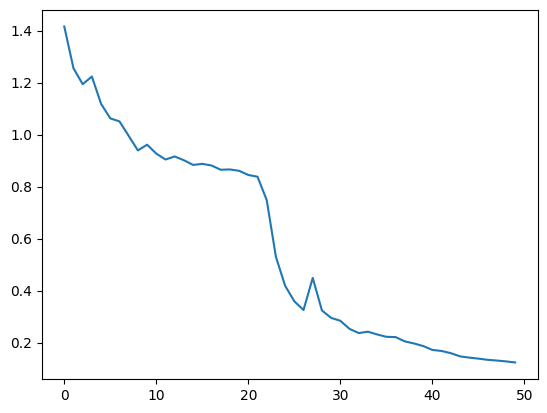

In [151]:
plt.plot(range(50),loss_log)

In [154]:
# Simple rule:
# - MSE (Regression): One numerical output per sample → target [N,1].
# - BCE (Binary): One binary output per sample → target [N,1].
# - CrossEntropy (Multiclass): Multiple class scores per sample → target [N] (class index).

#N x f =Nx 1 standard convention

In [155]:
#testing data

In [156]:
with torch.no_grad():#no backprop,just test,save memory
  y_eval=iris_LM1.forward(X_iris_test)
  loss_i=criterion_iris(y_eval,Y_iris_test)

In [160]:
loss_i.item()

0.1524638533592224

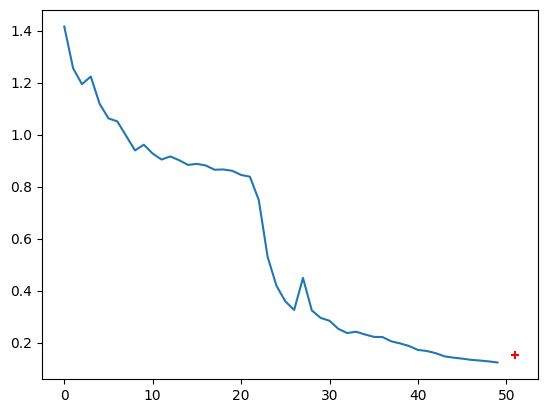

In [170]:
plt.plot(range(50),loss_log)
plt.scatter(x=51,y=loss_i.item(),color="red",marker="+")

In [172]:
prediction_y=[]
loss_y=[]
with torch.no_grad():#no backprop,just test,save memory
  for i,x_val in enumerate(X_iris_test):
    y_eval=iris_LM1.forward(x_val)
    print(i,y_eval,"\n")
    y_target=y_eval.argmax().item()
    prediction_y.append(y_target)
    loss_i=criterion_iris(y_eval,Y_iris_test[i])
    loss_y.append(loss_i)

0 tensor([41.1412, 15.6418,  0.0000,  0.0000]) 

1 tensor([35.8931, 13.6375,  0.0000,  0.0000]) 

2 tensor([24.6661,  9.2902,  0.0000,  0.0000]) 

3 tensor([0.0000, 6.9696, 8.1917, 0.0000]) 

4 tensor([0.0000, 2.5734, 0.0000, 0.0000]) 

5 tensor([0.0000, 7.4797, 9.2409, 0.0000]) 

6 tensor([0.0000, 6.1894, 6.5870, 0.0000]) 

7 tensor([0.0000, 4.4119, 2.9307, 0.0000]) 

8 tensor([ 0.0000,  8.8040, 11.9648,  0.0000]) 

9 tensor([30.2656, 11.8488,  0.0000,  0.0000]) 

10 tensor([ 0.0000,  8.3397, 11.0098,  0.0000]) 

11 tensor([40.0673, 15.2916,  0.0000,  0.0000]) 

12 tensor([30.3700, 11.6414,  0.0000,  0.0000]) 

13 tensor([ 0.0000, 11.4561, 17.4201,  0.0000]) 

14 tensor([0.0000, 6.9776, 8.2082, 0.0000]) 

15 tensor([0.0000, 2.4998, 0.0000, 0.0000]) 

16 tensor([0.0000, 2.7581, 0.0000, 0.0000]) 

17 tensor([0.0000, 3.1618, 0.3594, 0.0000]) 

18 tensor([30.6173, 11.9317,  0.0000,  0.0000]) 

19 tensor([ 0.0000,  7.8608, 10.0248,  0.0000]) 

20 tensor([0.0000, 2.5349, 0.0000, 0.0000]) 



In [173]:
print(prediction_y)

[0, 0, 0, 2, 1, 2, 2, 1, 2, 0, 2, 0, 0, 2, 2, 1, 1, 1, 0, 2, 1, 0, 1, 1, 1, 1, 1, 2, 0, 0, 2, 1, 2, 1, 2, 1, 1, 1, 1, 2, 0, 0, 0, 2, 1, 0, 2, 1, 0, 1]


In [174]:
from sklearn.metrics import classification_report


In [176]:
print(classification_report(prediction_y,Y_iris_test))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.91      1.00      0.95        20
           2       1.00      0.87      0.93        15

    accuracy                           0.96        50
   macro avg       0.97      0.96      0.96        50
weighted avg       0.96      0.96      0.96        50



In [181]:
model_path="/content/drive/My Drive/ml_repo/models"
torch.save(iris_LM1.state_dict(),f"{model_path}/irisNN.pt")

In [183]:
new_model=Irisnn(4,4,4,3)

In [184]:
new_model.load_state_dict(
    torch.load(f"{model_path}/irisNN.pt")
)

<All keys matched successfully>

In [186]:
torch.save(iris_LM1,f"{model_path}/irisNN2.pt")

In [187]:
# loaded_model = torch.load(
#     f"{model_path}/irisNN2.pt",
#     weights_only=False
# )

In [188]:
new_model.eval()

Irisnn(
  (fp1): Linear(in_features=4, out_features=4, bias=True)
  (fp2): Linear(in_features=4, out_features=4, bias=True)
  (out): Linear(in_features=4, out_features=4, bias=True)
)

In [189]:
#predictions = model(X_test)
#!__call__  mode and calls forward

In [190]:
# __call__() invokes forward(X_test).

In [191]:
loaded_model = torch.load(
    f"{model_path}/irisNN2.pt",
    weights_only=False
)

In [193]:
loaded_model.eval()

Irisnn(
  (fp1): Linear(in_features=4, out_features=4, bias=True)
  (fp2): Linear(in_features=4, out_features=4, bias=True)
  (out): Linear(in_features=4, out_features=4, bias=True)
)